# 05 · Test evaluation and statistics

The test set (FIFA 21, 3,288 players, 72 future elite) has not been used anywhere before this notebook.
Everything that decides **what** is evaluated was fixed on validation data first:

1. the five final feature sets (T6.2), by the rule in `src/final.py`
2. LightGBM retuned on each feature set with 50 TPE trials (T6.3), from `python scripts/run_hpo.py final`
3. the RQ1 models with their notebook-02 settings

Then every configuration is scored on the test set once (T6.4), followed by the validation-to-test gap (T6.5) and two sensitivity checks (T6.6).
Decision D31 records that this notebook was rerun after the first test evaluation only to fix formatting, never to change a model or a feature set.

In [1]:
import json
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
from sklearn.calibration import calibration_curve
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_recall_curve

from src import config, data, metrics, models, splits, tuning
from src.features import FEATURES, features_to_mask, pretty
from src.final import CONFIG_LABEL, CONFIGS, final_feature_sets
from src.fitness import FitnessFunction, bits_to_mask
from src.plotting import (AQUA, BLUE, GRAY, INK, INK_SECONDARY, MUTED, ORANGE, METHOD_STYLE, plt, save,
                          set_style)

set_style()
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 160)
TABLES = config.RESULTS / "tables"

df = data.load_main()
y_train = df.loc[df["set"] == "train", "y"].to_numpy().astype(int)
y_val = df.loc[df["set"] == "val", "y"].to_numpy().astype(int)
y_test = df.loc[df["set"] == "test", "y"].to_numpy().astype(int)
print(f"test: {len(y_test)} rows, {y_test.sum()} positives ({y_test.mean():.2%}); the PR-AUC of a random ranking is about {y_test.mean():.3f}")

test: 3288 rows, 72 positives (2.19%); the PR-AUC of a random ranking is about 0.022


## 1. The five final feature sets (T6.2)

Rules (decision D30), applied to validation results only:

* **GA, Binary PSO, Binary GWO**: the subset of the run with the best validation fitness among that optimizer's 10 runs at α = 0.99.
* **SHAP top-k**: the k features with the largest mean |SHAP| of the tuned all-feature LightGBM on the **validation** set, k = the median size of the three subsets above.
* **All 45 features.**

In [2]:
sets = final_feature_sets()
meta = sets["_meta"]
print("chosen runs (seed, validation fitness):", {a: (meta["chosen_seeds"][a], round(meta["chosen_fitness"][a], 5)) for a in ("ga", "bpso", "bgwo")})
print("k for SHAP top-k:", meta["k"])
overview = pd.DataFrame({
    "features": [len(sets[c]) for c in CONFIGS],
    "contains current overall": ["overall" in sets[c] for c in CONFIGS],
    "contains age": ["age" in sets[c] for c in CONFIGS],
    "feature list": [", ".join(pretty(f) for f in sets[c]) if c != "all" else "all 45" for c in CONFIGS],
}, index=[CONFIG_LABEL[c] for c in CONFIGS])
overview

chosen runs (seed, validation fitness): {'ga': (9, 0.36615), 'bpso': (6, 0.36307), 'bgwo': (7, 0.36231)}
k for SHAP top-k: 20


,features,contains current overall,contains age,feature list
All 45 features,45,True,True,all 45
GA subset,20,True,True,"Overall (current), Age, Height, Position group, Shooting (face), Crossing, Heading accuracy, Short passing, Volleys, Curve, Long passing, Ball control, Spri..."
Binary PSO subset,21,False,True,"Age, Height, Preferred foot, Weak foot, Position group, Overall change (1 yr), Shooting (face), Passing (face), Crossing, Finishing, Short passing, Volleys,..."
Binary GWO subset,16,False,True,"Age, Height, Preferred foot, Overall change (1 yr), Pace (face), Passing (face), Volleys, FK accuracy, Ball control, Agility, Shot power, Jumping, Vision, P..."
SHAP top-k,20,True,True,"Age, Reactions, FK accuracy, Overall (current), Sprint speed, Short passing, Heading accuracy, Height, Positioning, Marking awareness, Jumping, Interception..."


In [3]:
subset_names = ["ga", "bpso", "bgwo", "shap_top_k"]
jac = pd.DataFrame([[len(set(sets[a]) & set(sets[b])) / len(set(sets[a]) | set(sets[b])) for b in subset_names] for a in subset_names],
                   index=[CONFIG_LABEL[c] for c in subset_names], columns=[CONFIG_LABEL[c] for c in subset_names])
print("Jaccard similarity between the final subsets")
jac.round(2)

Jaccard similarity between the final subsets


,GA subset,Binary PSO subset,Binary GWO subset,SHAP top-k
GA subset,1.00,0.52,0.29,0.33
Binary PSO subset,0.52,1.00,0.42,0.32
Binary GWO subset,0.29,0.42,1.00,0.29
SHAP top-k,0.33,0.32,0.29,1.00


## 2. LightGBM retuned on each feature set (T6.3)

The fixed fitness settings (200 trees, learning rate 0.05) were chosen for speed. Each final feature set gets its own TPE study (50 trials, seed 0, same search space as notebook 02), so every configuration is compared with tuned settings, as the all-feature model was.
For all 45 features this is the seed-0 study from notebook 02.

In [4]:
X = {s: data.get_xy(df, s)[0] for s in ("train", "val", "test")}
fixed = FitnessFunction(X["train"], y_train, X["val"], y_val)
lgbm, params, rows = {}, {}, []
for c in CONFIGS:
    cols = sets[c]
    path = config.HPO_DIR / ("lgbm_tpe_seed0.csv" if c == "all" else f"final_lgbm_{c}_tpe_seed0.csv")
    study = tuning.run_study("lgbm", "tpe", 0, X["train"][cols], y_train, X["val"][cols], y_val, path)
    params[c] = tuning.best_params(study)
    lgbm[c] = models.fit("lgbm", params[c], X["train"][cols], y_train)
    fixed(features_to_mask(cols))
    rows.append({"configuration": CONFIG_LABEL[c], "features": len(cols),
                 "val PR-AUC, fixed fitness settings": fixed.log[-1]["pr_auc"],
                 "val PR-AUC, tuned": metrics.pr_auc(y_val, models.scores(lgbm[c], X["val"][cols])),
                 "study best (check)": study["value"].max()})
retuned = pd.DataFrame(rows).set_index("configuration")
retuned.round(4)

,features,"val PR-AUC, fixed fitness settings","val PR-AUC, tuned",study best (check)
configuration,,,,
All 45 features,45,0.4993,0.5932,0.5932
GA subset,20,0.6346,0.6360,0.6360
Binary PSO subset,21,0.6380,0.6497,0.6497
Binary GWO subset,16,0.6376,0.6243,0.6243
SHAP top-k,20,0.5513,0.5915,0.5915


**The "best subset"** reported as a headline number is fixed here, before the test set is used: the subset configuration with the highest tuned validation PR-AUC.

In [5]:
best_subset = max(subset_names, key=lambda c: retuned.loc[CONFIG_LABEL[c], "val PR-AUC, tuned"])
print("best subset by tuned validation PR-AUC:", CONFIG_LABEL[best_subset], f"({len(sets[best_subset])} features)")

best subset by tuned validation PR-AUC: Binary PSO subset (21 features)


## 3. RQ1 models with their notebook-02 settings

In [6]:
rq1 = {}
for name in ["logreg", "rf", "mlp"]:
    p = tuning.load_params(config.HPO_DIR / f"best_params_{name}.json")
    rq1[name] = models.fit(name, p, X["train"], y_train, X["val"], y_val)
rq1["lgbm"] = lgbm["all"]
val_check = {models.MODEL_LABEL[n]: metrics.pr_auc(y_val, models.scores(m, X["val"])) for n, m in rq1.items()}
val_check["EA potential"] = metrics.pr_auc(y_val, df.loc[df["set"] == "val", "potential"])
pd.Series(val_check, name="validation PR-AUC (matches notebook 02)").round(4).to_frame()

,validation PR-AUC (matches notebook 02)
Logistic regression,0.5316
Random forest,0.5388
MLP,0.5728
LightGBM,0.5932
EA potential,0.4232


## 4. Test evaluation, once per configuration (T6.4)

Every model below was fitted on the training set only. Metrics:

* **PR-AUC** with a 95% percentile bootstrap interval (1,000 resamples of test rows)
* ROC-AUC
* **Precision@50 and Recall@50**: the 50 highest-scored test players as a scout's shortlist
* **Brier score** of the predicted probabilities, raw and after Platt scaling fitted on validation scores (class weights inflate raw probabilities, so the raw Brier score is expected to be poor)

In [7]:
test = df[df["set"] == "test"].reset_index(drop=True)
scores = pd.DataFrame({"player_id": test["player_id"], "short_name": test["short_name"], "y": y_test})
val_scores = {}
scores["potential"] = test["potential"].to_numpy()
for name in ["logreg", "rf", "mlp"]:
    scores[name] = models.scores(rq1[name], X["test"])
    val_scores[name] = models.scores(rq1[name], X["val"])
for c in CONFIGS:
    scores[f"lgbm_{c}"] = models.scores(lgbm[c], X["test"][sets[c]])
    val_scores[f"lgbm_{c}"] = models.scores(lgbm[c], X["val"][sets[c]])
scores.to_csv(config.FINAL_DIR / "test_predictions.csv", index=False)

CFG_SHORT = {"all": "all 45 features", "ga": "GA subset", "bpso": "Binary PSO subset", "bgwo": "Binary GWO subset",
             "shap_top_k": f"SHAP top-{meta['k']}"}
ROW_LABEL = {"potential": "EA potential (baseline)", "logreg": "Logistic regression", "rf": "Random forest",
             "mlp": "MLP", **{f"lgbm_{c}": f"LightGBM, {CFG_SHORT[c]}" for c in CONFIGS}}


def platt_brier(name):
    """Brier score after a logistic recalibration fitted on validation scores."""
    logit = lambda p: np.log(np.clip(p, 1e-6, 1 - 1e-6) / (1 - np.clip(p, 1e-6, 1 - 1e-6)))
    cal = LogisticRegression().fit(logit(val_scores[name]).reshape(-1, 1), y_val)
    return metrics.brier(y_test, cal.predict_proba(logit(scores[name].to_numpy()).reshape(-1, 1))[:, 1])


results = []
for name, label in ROW_LABEL.items():
    s = scores[name].to_numpy()
    rep = metrics.full_report(y_test, s, probabilities=None if name == "potential" else s)
    rep["brier_platt"] = np.nan if name == "potential" else platt_brier(name)
    rep["configuration"] = label
    results.append(rep)
results = pd.DataFrame(results).set_index("configuration")[
    ["pr_auc", "pr_auc_lo", "pr_auc_hi", "roc_auc", "precision_at_50", "recall_at_50", "brier", "brier_platt"]]
results.round(4).to_csv(TABLES / "test_results.csv")
results.round(4)

,pr_auc,pr_auc_lo,pr_auc_hi,roc_auc,precision_at_50,recall_at_50,brier,brier_platt
configuration,,,,,,,,
EA potential (baseline),0.3272,0.2332,0.4463,0.9126,0.56,0.3889,NaN,NaN
Logistic regression,0.3019,0.2166,0.4117,0.9249,0.32,0.2222,0.1131,0.0187
Random forest,0.3526,0.2541,0.4822,0.9229,0.44,0.3056,0.0460,0.0170
MLP,0.3071,0.2220,0.4186,0.9223,0.36,0.2500,0.1299,0.0184
"LightGBM, all 45 features",0.3009,0.2053,0.4201,0.8948,0.44,0.3056,0.0207,0.0188
"LightGBM, GA subset",0.2957,0.2094,0.4215,0.9156,0.36,0.2500,0.0240,0.0183
"LightGBM, Binary PSO subset",0.3127,0.2215,0.4348,0.8887,0.42,0.2917,0.0194,0.0187
"LightGBM, Binary GWO subset",0.2838,0.2065,0.4053,0.9014,0.48,0.3333,0.0197,0.0185
"LightGBM, SHAP top-20",0.2905,0.2038,0.4030,0.8998,0.40,0.2778,0.0215,0.0192


In [8]:
diff_pairs = [("lgbm_all", "potential", "H1b: LightGBM vs EA potential"),
              ("lgbm_all", "mlp", "H1a: LightGBM vs MLP"),
              ("lgbm_all", "logreg", "LightGBM vs logistic regression"),
              ("mlp", "potential", "MLP vs EA potential")] + \
             [(f"lgbm_{c}", "lgbm_all", f"{CONFIG_LABEL[c]} vs all 45 features") for c in subset_names]
diffs = []
for a, b, label in diff_pairs:
    point, lo, hi = metrics.paired_bootstrap_diff(y_test, scores[a].to_numpy(), scores[b].to_numpy())
    diffs.append({"comparison": label, "PR-AUC difference": point, "95% CI low": lo, "95% CI high": hi,
                  "interval excludes 0": lo > 0 or hi < 0})
diffs = pd.DataFrame(diffs).set_index("comparison")
diffs.round(4).to_csv(TABLES / "test_paired_differences.csv")
diffs.round(4)

,PR-AUC difference,95% CI low,95% CI high,interval excludes 0
comparison,,,,
H1b: LightGBM vs EA potential,-0.0263,-0.1159,0.0586,False
H1a: LightGBM vs MLP,-0.0062,-0.0902,0.0835,False
LightGBM vs logistic regression,-0.0010,-0.0811,0.0793,False
MLP vs EA potential,-0.0201,-0.1049,0.0620,False
GA subset vs all 45 features,-0.0052,-0.0621,0.0583,False
Binary PSO subset vs all 45 features,0.0118,-0.0682,0.0974,False
Binary GWO subset vs all 45 features,-0.0171,-0.0916,0.0515,False
SHAP top-k vs all 45 features,-0.0104,-0.0630,0.0395,False


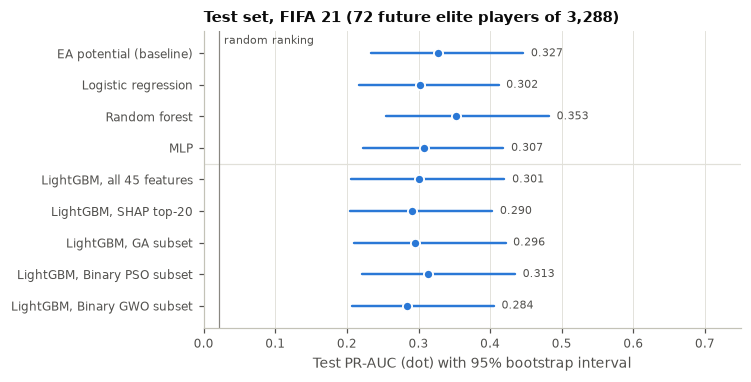

In [9]:
order = ["potential", "logreg", "rf", "mlp", "lgbm_all", "lgbm_shap_top_k", "lgbm_ga", "lgbm_bpso", "lgbm_bgwo"]
fig, ax = plt.subplots(figsize=(6.3, 3.5))
ypos = np.arange(len(order))[::-1]
for y, name in zip(ypos, order):
    r = results.loc[ROW_LABEL[name]]
    ax.plot([r["pr_auc_lo"], r["pr_auc_hi"]], [y, y], color=BLUE, linewidth=1.6, solid_capstyle="round")
    ax.plot(r["pr_auc"], y, "o", color=BLUE, markersize=6, markeredgecolor="white", markeredgewidth=1.2)
    ax.annotate(f"{r['pr_auc']:.3f}", (r["pr_auc_hi"], y), xytext=(5, 0), textcoords="offset points", va="center",
                fontsize=7.5, color=INK_SECONDARY)
ax.axhline(4.5 - 0.0, color="#e1e0d9", linewidth=0.8)
ax.axvline(y_test.mean(), color=MUTED, linewidth=0.8)
ax.annotate("random ranking", (y_test.mean(), len(order) - 0.6), xytext=(3, 0), textcoords="offset points",
            fontsize=7.5, color=INK_SECONDARY, va="center")
ax.set_yticks(ypos, [ROW_LABEL[n] for n in order])
ax.set(xlabel="Test PR-AUC (dot) with 95% bootstrap interval", xlim=(0, 0.75), ylim=(-0.7, len(order) - 0.3),
       title="Test set, FIFA 21 (72 future elite players of 3,288)")
ax.grid(axis="y", visible=False)
save(fig, "fig05a_test_pr_auc")
plt.show()

### Shortlist view and calibration

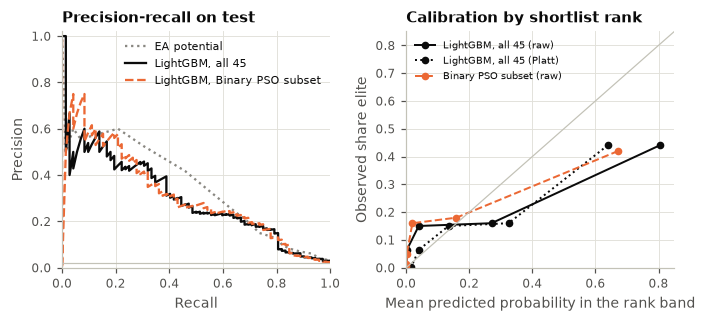

Brier score of always predicting the base rate: 0.0214


,mean predicted,observed share elite
ranks 1-50,0.803,0.440
ranks 51-100,0.271,0.160
ranks 101-200,0.040,0.150
ranks 201-400,0.003,0.065
ranks 401-800,0.000,0.002
ranks 801-3288,0.000,0.005


mean predicted  observed rate  calibration slope   Brier
model                       probabilities                                                                         
Logistic regression         raw                                   0.2516         0.0219             1.1500  0.1131
                            Platt (fitted on validation)          0.0256         0.0219             0.7291  0.0187
Random forest               raw                                   0.1240         0.0219             1.0843  0.0460
                            Platt (fitted on validation)          0.0213         0.0219             0.8176  0.0170
MLP                         raw                                   0.2683         0.0219             1.2808  0.1299
                            Platt (fitted on validation)          0.0239         0.0219             0.6883  0.0184
LightGBM, all 45 features   raw                                   0.0178         0.0219             0.3877  0.0207
                            Platt (fitted on validation)          0.0259         0.0219             0.8087  0.0188
LightGBM, Binary PSO subset raw                                   0.0134         0.0219             0.4206  0.0194
                            Platt (fitted on validation)          0.0250         0.0219             0.7844  0.0187

In [10]:
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(6.3, 3.0))
curve_style = {"potential": dict(color=MUTED, linestyle=":", label="EA potential"),
               "lgbm_all": dict(color=INK, linestyle="-", label="LightGBM, all 45"),
               f"lgbm_{best_subset}": dict(color=METHOD_STYLE.get(best_subset, {"color": BLUE})["color"], linestyle="--",
                                           label=f"LightGBM, {CFG_SHORT[best_subset]}")}
for name, kw in curve_style.items():
    precision, recall, _ = precision_recall_curve(y_test, scores[name])
    ax.plot(recall, precision, linewidth=1.5, **kw)
ax.axhline(y_test.mean(), color="#c3c2b7", linewidth=0.8)
ax.set(xlabel="Recall", ylabel="Precision", title="Precision-recall on test", xlim=(0, 1), ylim=(0, 1.02))
ax.legend(loc="upper right", fontsize=7)

RANK_EDGES = [0, 50, 100, 200, 400, 800, len(y_test)]


def platt_probabilities(name):
    logit = lambda p: np.log(np.clip(p, 1e-6, 1 - 1e-6) / (1 - np.clip(p, 1e-6, 1 - 1e-6)))
    cal = LogisticRegression().fit(logit(val_scores[name]).reshape(-1, 1), y_val)
    return cal.predict_proba(logit(scores[name].to_numpy()).reshape(-1, 1))[:, 1]


def rank_bins(y, p):
    order = np.argsort(-np.asarray(p), kind="stable")
    ys, ps = np.asarray(y)[order], np.asarray(p)[order]
    return [(ps[lo:hi].mean(), ys[lo:hi].mean()) for lo, hi in zip(RANK_EDGES[:-1], RANK_EDGES[1:])]


calibration_series = {"LightGBM, all 45 (raw)": (scores["lgbm_all"].to_numpy(), dict(color=INK, linestyle="-")),
                      "LightGBM, all 45 (Platt)": (platt_probabilities("lgbm_all"), dict(color=INK, linestyle=":")),
                      f"{CFG_SHORT[best_subset]} (raw)": (scores[f"lgbm_{best_subset}"].to_numpy(),
                                                    dict(color=curve_style[f"lgbm_{best_subset}"]["color"], linestyle="--"))}
for label, (p, kw) in calibration_series.items():
    pts = np.array(rank_bins(y_test, p))
    ax2.plot(pts[:, 0], pts[:, 1], marker="o", markersize=4, linewidth=1.3,
             label=label, **kw)
ax2.plot([0, 1], [0, 1], color="#c3c2b7", linewidth=0.8)
ax2.set(xlabel="Mean predicted probability in the rank band", ylabel="Observed share elite",
        title="Calibration by shortlist rank", xlim=(0, 0.85), ylim=(0, 0.85))
ax2.legend(loc="upper left", fontsize=6.5)
fig.tight_layout()
save(fig, "fig05b_pr_curves_calibration")
plt.show()

calibration = []
for name in ["logreg", "rf", "mlp", "lgbm_all", f"lgbm_{best_subset}"]:
    for kind, p in (("raw", scores[name].to_numpy()), ("Platt (fitted on validation)", platt_probabilities(name))):
        logit = np.log(np.clip(p, 1e-6, 1 - 1e-6) / (1 - np.clip(p, 1e-6, 1 - 1e-6)))
        slope = LogisticRegression(C=1e6).fit(logit.reshape(-1, 1), y_test).coef_[0, 0]
        calibration.append({"model": ROW_LABEL[name], "probabilities": kind, "mean predicted": p.mean(),
                            "observed rate": y_test.mean(), "calibration slope": slope, "Brier": metrics.brier(y_test, p)})
calibration = pd.DataFrame(calibration).set_index(["model", "probabilities"])
calibration.round(4).to_csv(TABLES / "test_calibration.csv")
print(f"Brier score of always predicting the base rate: {y_test.mean() * (1 - y_test.mean()):.4f}")
rank_table = pd.DataFrame(rank_bins(y_test, scores["lgbm_all"]), columns=["mean predicted", "observed share elite"],
                          index=[f"ranks {lo + 1}-{hi}" for lo, hi in zip(RANK_EDGES[:-1], RANK_EDGES[1:])])
display(rank_table.round(3))
calibration.round(4)

## 5. Validation-to-test gap (T6.5)

The optimizers looked at validation PR-AUC thousands of times, and the final models were tuned on validation too, so validation scores are optimistic.
The gap below is validation minus test PR-AUC for the same fitted model.

In [11]:
gap_rows = []
for c in CONFIGS:
    label = CONFIG_LABEL[c]
    gap_rows.append({"configuration": ROW_LABEL[f"lgbm_{c}"], "features": len(sets[c]),
                     "val PR-AUC at selection (fixed settings)": retuned.loc[label, "val PR-AUC, fixed fitness settings"],
                     "val PR-AUC (tuned)": retuned.loc[label, "val PR-AUC, tuned"],
                     "test PR-AUC": results.loc[ROW_LABEL[f"lgbm_{c}"], "pr_auc"]})
for name in ["logreg", "rf", "mlp"]:
    gap_rows.append({"configuration": ROW_LABEL[name], "features": 45,
                     "val PR-AUC (tuned)": metrics.pr_auc(y_val, val_scores[name]),
                     "test PR-AUC": results.loc[ROW_LABEL[name], "pr_auc"]})
gap_rows.append({"configuration": ROW_LABEL["potential"], "features": 1,
                 "val PR-AUC (tuned)": val_check["EA potential"], "test PR-AUC": results.loc[ROW_LABEL["potential"], "pr_auc"]})
gap = pd.DataFrame(gap_rows).set_index("configuration")
gap["gap (val tuned - test)"] = gap["val PR-AUC (tuned)"] - gap["test PR-AUC"]
gap.round(4).to_csv(TABLES / "val_test_gap.csv")
gap.round(4)

,features,val PR-AUC at selection (fixed settings),val PR-AUC (tuned),test PR-AUC,gap (val tuned - test)
configuration,,,,,
"LightGBM, all 45 features",45,0.4993,0.5932,0.3009,0.2923
"LightGBM, GA subset",20,0.6346,0.6360,0.2957,0.3403
"LightGBM, Binary PSO subset",21,0.6380,0.6497,0.3127,0.3370
"LightGBM, Binary GWO subset",16,0.6376,0.6243,0.2838,0.3405
"LightGBM, SHAP top-20",20,0.5513,0.5915,0.2905,0.3011
Logistic regression,45,NaN,0.5316,0.3019,0.2297
Random forest,45,NaN,0.5388,0.3526,0.1861
MLP,45,NaN,0.5728,0.3071,0.2657
EA potential (baseline),1,NaN,0.4232,0.3272,0.0960


### Why validation was so much easier than test

Even EA's potential rating, which involves no fitting at all, drops from 0.42 on validation to 0.33 on test. So part of the gap is not overfitting: the validation set itself is unusual.
Decision D10 already warned why: removing every test player from validation removes exactly the players who, in FIFA 21, were still 21 or younger and still below 80.
The validation players who remain had, by FIFA 21, turned 22, reached 80 or left the game.
The table compares the FIFA 19-20 rows that stayed in validation with the FIFA 19-20 rows that were removed, and with test. Only EA potential and the training-set fit are used; no test-set model is fitted here.

In [12]:
labelled = data.load_labelled()
labelled = labelled[~labelled["missing_future"]]
v1920 = labelled[labelled["fifa_version"].between(*config.VAL_VERSIONS)].copy()
test_players = set(df.loc[df["set"] == "test", "player_id"])
v1920["group"] = np.where(v1920["player_id"].isin(test_players), "FIFA 19-20 rows removed (players in test)",
                          "FIFA 19-20 rows kept (validation)")
groups = {g: part for g, part in v1920.groupby("group")}
groups["all FIFA 19-20 rows"] = v1920
groups["test (FIFA 21)"] = test

model_all = lgbm["all"]
diag_rows = []
for name, part in groups.items():
    y = part["y"].to_numpy().astype(int)
    pos = part[part["y"] == 1]
    row = {"rows": len(part), "positives": int(y.sum()), "positive rate": y.mean(), "mean age": part["age"].mean(),
           "share aged 21": (part["age"] == 21).mean(), "positives: mean overall at t": pos["overall"].mean(),
           "positives: share already 75+": (pos["overall"] >= 75).mean(),
           "EA potential PR-AUC": metrics.pr_auc(y, part["potential"])}
    if not name.startswith("test"):
        row["tuned LightGBM PR-AUC"] = metrics.pr_auc(y, models.scores(model_all, part[FEATURES].astype("float64")))
    diag_rows.append(pd.Series(row, name=name))
diagnostic = pd.DataFrame(diag_rows)
diagnostic.round(3).to_csv(TABLES / "validation_vs_test_diagnostic.csv")
diagnostic.round(3)

,rows,positives,positive rate,mean age,share aged 21,positives: mean overall at t,positives: share already 75+,EA potential PR-AUC,tuned LightGBM PR-AUC
FIFA 19-20 rows kept (validation),3974.0,113.0,0.028,20.139,0.498,74.690,0.628,0.423,0.593
FIFA 19-20 rows removed (players in test),2426.0,43.0,0.018,18.822,0.001,70.837,0.326,0.211,0.186
all FIFA 19-20 rows,6400.0,156.0,0.024,19.640,0.310,73.628,0.545,0.303,0.474
test (FIFA 21),3288.0,72.0,0.022,19.613,0.290,72.514,0.458,0.327,NaN


In [13]:
from src.fitness import CVFitnessFunction
from src.features import D

cv_all = CVFitnessFunction(X["train"], y_train, df.loc[df["set"] == "train", "player_id"].to_numpy())
cv_all(np.ones(D, dtype=np.uint8))
print(f"all 45 features, fixed settings: validation PR-AUC {retuned.loc['All 45 features', 'val PR-AUC, fixed fitness settings']:.3f}, "
      f"3-fold grouped CV on train {cv_all.log[-1]['pr_auc']:.3f}, test {FitnessFunction(X['train'], y_train, X['test'], y_test).train_and_score(np.ones(D, dtype=np.uint8)):.3f}")

all 45 features, fixed settings: validation PR-AUC 0.499, 3-fold grouped CV on train 0.320, test 0.312


## 6. Sensitivity checks (T6.6)

* **(a) Missing players as negatives.** The 6,502 eligible rows whose player is absent from all three future versions were dropped. Here they count as 0, the split is rebuilt with the same rules, and the models are refitted on the new training set.
* **(b) A second label, 75+ within three versions.** Features and label both come from EA ratings; if the conclusions only hold at exactly 80, that circularity would matter more.

Both checks reuse the hyperparameters tuned for the main label (no retuning) and compare LightGBM on all features, LightGBM on the best subset and EA potential.

In [14]:
sens_scores = {}


def sensitivity_row(frame, label_col, setting):
    out = []
    sens_scores[setting] = {}
    y_tr = frame.loc[frame["set"] == "train", label_col].to_numpy().astype(int)
    y_te = frame.loc[frame["set"] == "test", label_col].to_numpy().astype(int)
    for name, cols, p in (("LightGBM, all 45 features", FEATURES, params["all"]),
                          (ROW_LABEL[f"lgbm_{best_subset}"], sets[best_subset], params[best_subset])):
        model = models.fit("lgbm", p, frame.loc[frame["set"] == "train", cols].astype("float64"), y_tr)
        s = models.scores(model, frame.loc[frame["set"] == "test", cols].astype("float64"))
        sens_scores[setting][name] = (y_te, s)
        lo, hi = metrics.bootstrap_ci(y_te, s)
        out.append({"setting": setting, "model": name, "test rows": len(y_te), "test positives": int(y_te.sum()),
                    "positive rate": y_te.mean(), "test PR-AUC": metrics.pr_auc(y_te, s), "95% CI low": lo, "95% CI high": hi})
    s = frame.loc[frame["set"] == "test", "potential"].to_numpy()
    sens_scores[setting]["EA potential"] = (y_te, s)
    lo, hi = metrics.bootstrap_ci(y_te, s)
    out.append({"setting": setting, "model": "EA potential", "test rows": len(y_te), "test positives": int(y_te.sum()),
                "positive rate": y_te.mean(), "test PR-AUC": metrics.pr_auc(y_te, s), "95% CI low": lo, "95% CI high": hi})
    return out


full = data.load_labelled()
missing_as_negative = full.copy()
missing_as_negative["y"] = missing_as_negative["y"].fillna(0.0)
missing_as_negative["set"] = splits.temporal_group_split(missing_as_negative)
splits.check_split(missing_as_negative[missing_as_negative["set"].isin(splits.SETS)])

sens = pd.DataFrame(
    sensitivity_row(df, "y", "main (80+, missing dropped)")
    + sensitivity_row(missing_as_negative, "y", "(a) 80+, missing counted as 0")
    + sensitivity_row(df, f"y{config.SECOND_THRESHOLD}", f"(b) {config.SECOND_THRESHOLD}+, missing dropped"))
sens["lift over random"] = sens["test PR-AUC"] / sens["positive rate"]
sens.round(4).to_csv(TABLES / "sensitivity.csv", index=False)
display(sens.round(4))

paired = []
for setting, d in sens_scores.items():
    y_te, s_model = d["LightGBM, all 45 features"]
    _, s_pot = d["EA potential"]
    point, lo, hi = metrics.paired_bootstrap_diff(y_te, s_model, s_pot)
    paired.append({"setting": setting, "LightGBM (all 45) minus EA potential": point, "95% CI low": lo, "95% CI high": hi})
pd.DataFrame(paired).round(4)

,setting,model,test rows,test positives,positive rate,test PR-AUC,95% CI low,95% CI high,lift over random
0,"main (80+, missing dropped)","LightGBM, all 45 features",3288,72,0.0219,0.3009,0.2053,0.4201,13.7395
1,"main (80+, missing dropped)","LightGBM, Binary PSO subset",3288,72,0.0219,0.3127,0.2215,0.4348,14.2783
2,"main (80+, missing dropped)",EA potential,3288,72,0.0219,0.3272,0.2332,0.4463,14.9418
3,"(a) 80+, missing counted as 0","LightGBM, all 45 features",4304,72,0.0167,0.3139,0.2150,0.4400,18.7628
4,"(a) 80+, missing counted as 0","LightGBM, Binary PSO subset",4304,72,0.0167,0.3188,0.2246,0.4431,19.0585
5,"(a) 80+, missing counted as 0",EA potential,4304,72,0.0167,0.3260,0.2253,0.4584,19.4868
6,"(b) 75+, missing dropped","LightGBM, all 45 features",3288,336,0.1022,0.5994,0.5477,0.6480,5.8654
7,"(b) 75+, missing dropped","LightGBM, Binary PSO subset",3288,336,0.1022,0.6079,0.5528,0.6585,5.9488
8,"(b) 75+, missing dropped",EA potential,3288,336,0.1022,0.5191,0.4674,0.5726,5.0794


,setting,LightGBM (all 45) minus EA potential,95% CI low,95% CI high
0,"main (80+, missing dropped)",-0.0263,-0.1159,0.0586
1,"(a) 80+, missing counted as 0",-0.0121,-0.1064,0.0746
2,"(b) 75+, missing dropped",0.0803,0.0358,0.1263


## 7. Fallback from plan §9: choosing features by grouped cross-validation on train

The plan's fallback for a large validation-to-test drop: rerun the selection with a fitness that never touches validation, namely the mean PR-AUC over 3 player-grouped folds of the training set (`src/fitness.py`, `CVFitnessFunction`), same fixed LightGBM settings, same α, budget and starting populations.
GA, Binary PSO and Binary GWO were run with seeds 0 to 3 (`python run_experiments.py --algs ga bpso bgwo --seeds 0 1 2 3 --fitness cv --out results/fallback_cv_fitness`).

This is a diagnostic of the **selection criterion**, run after the gap above was seen, so it uses the test set as a measuring stick for many subsets at once. No subset from this section is promoted to a final model.
Every subset is scored with the same fixed LightGBM settings on three data sets: grouped CV on train, validation and test.

In [15]:
fb_dir = config.RESULTS / "fallback_cv_fitness"
fixed_test = FitnessFunction(X["train"], y_train, X["test"], y_test)


def three_scores(mask):
    return {"CV on train": cv_all.pr_auc(mask)[0], "validation": fixed.pr_auc(mask)[0], "test": fixed_test.pr_auc(mask)[0]}


rows = []
for criterion, folder, seeds in (("validation", config.FS_DIR, list(config.RUN_SEEDS)), ("CV on train", fb_dir, [0, 1, 2, 3])):
    for alg in ("ga", "bpso", "bgwo"):
        for seed in seeds:
            summary = json.loads((folder / f"{alg}_seed{seed}.json").read_text())
            mask = bits_to_mask(summary["best_mask"])
            rows.append({"selected by": criterion, "algorithm": METHOD_STYLE[alg]["label"], "seed": seed,
                         "features": int(mask.sum()), **{f"PR-AUC, {k}": v for k, v in three_scores(mask).items()}})
fallback = pd.DataFrame(rows)
reference_all = three_scores(np.ones(D, dtype=np.uint8))
fallback.to_csv(TABLES / "fallback_cv_subsets.csv", index=False)

fb_summary = fallback.groupby(["selected by", "algorithm"]).agg(
    runs=("seed", "size"), features=("features", "mean"),
    cv=("PR-AUC, CV on train", "mean"), val=("PR-AUC, validation", "mean"), test=("PR-AUC, test", "mean"),
    test_min=("PR-AUC, test", "min"), test_max=("PR-AUC, test", "max"))
fb_summary.loc[("reference", "all 45 features"), :] = [1, 45, reference_all["CV on train"], reference_all["validation"],
                                                         reference_all["test"], reference_all["test"], reference_all["test"]]
fb_summary.round(4)

runs  features      cv     val    test  test_min  test_max
selected by algorithm                                                                  
CV on train Binary GWO          4      16.0  0.3657  0.5066  0.2634    0.2288    0.2884
            Binary PSO          4      22.5  0.3646  0.5276  0.2815    0.2703    0.2965
            GA                  4      19.0  0.3724  0.4998  0.2949    0.2714    0.3262
validation  Binary GWO         10      17.9  0.2755  0.6270  0.2851    0.2534    0.3336
            Binary PSO         10      21.6  0.2718  0.6214  0.3147    0.2669    0.3668
            GA                 10      22.1  0.2774  0.6122  0.2855    0.2321    0.3470
reference   all 45 features     1      45.0  0.3201  0.4993  0.3120    0.3120    0.3120

In [16]:
from scipy.stats import mannwhitneyu

a = fallback.loc[fallback["selected by"] == "validation", "PR-AUC, test"]
b = fallback.loc[fallback["selected by"] == "CV on train", "PR-AUC, test"]
test_mw = mannwhitneyu(b, a, alternative="two-sided")
print(f"test PR-AUC, subsets chosen on validation: mean {a.mean():.4f} (n = {len(a)}); chosen by CV on train: mean {b.mean():.4f} (n = {len(b)})")
print(f"Mann-Whitney U = {test_mw.statistic:.0f}, p = {test_mw.pvalue:.4f}")
print(f"subsets beating all 45 features on test (fixed settings): validation-chosen {(a > reference_all['test']).sum()} of {len(a)}, "
      f"CV-chosen {(b > reference_all['test']).sum()} of {len(b)}")

test PR-AUC, subsets chosen on validation: mean 0.2951 (n = 30); chosen by CV on train: mean 0.2799 (n = 12)
Mann-Whitney U = 138, p = 0.2479
subsets beating all 45 features on test (fixed settings): validation-chosen 10 of 30, CV-chosen 1 of 12


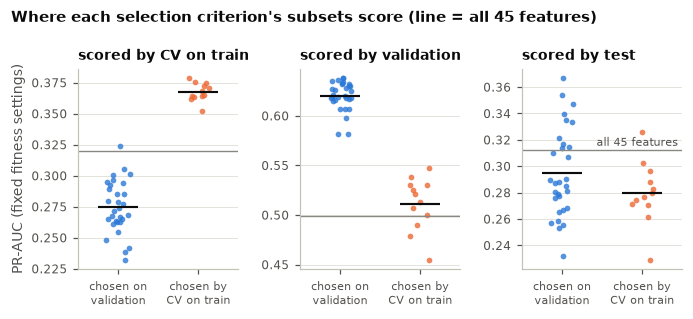

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(6.3, 2.9), sharey=False)
jit = np.random.default_rng(3)
for ax, metric in zip(axes, ["PR-AUC, CV on train", "PR-AUC, validation", "PR-AUC, test"]):
    for i, criterion in enumerate(["validation", "CV on train"]):
        vals = fallback.loc[fallback["selected by"] == criterion, metric].to_numpy()
        color = BLUE if criterion == "validation" else ORANGE
        ax.scatter(i + jit.uniform(-0.15, 0.15, len(vals)), vals, s=14, color=color, alpha=0.8, linewidths=0)
        ax.hlines(vals.mean(), i - 0.25, i + 0.25, color=INK, linewidth=1.4)
    ref = reference_all[metric.split(", ")[1]]
    ax.axhline(ref, color=MUTED, linewidth=0.9)
    ax.set_xticks([0, 1], ["chosen on\nvalidation", "chosen by\nCV on train"], fontsize=7.5)
    ax.set_title(f"scored by {metric.split(', ')[1]}", fontsize=9)
    ax.grid(axis="x", visible=False)
    ax.set_xlim(-0.5, 1.5)
axes[0].set_ylabel("PR-AUC (fixed fitness settings)")
axes[2].annotate("all 45 features", (1.45, reference_all["test"]), xytext=(0, 3), textcoords="offset points", ha="right",
                 fontsize=7, color=INK_SECONDARY)
fig.suptitle("Where each selection criterion's subsets score (line = all 45 features)", x=0.01, ha="left",
             fontsize=10, fontweight="bold")
fig.tight_layout()
save(fig, "fig05c_fallback_cv_selection")
plt.show()

## 8. Summary

**RQ1 on the test season.** Every scorer lands between 0.28 and 0.35 PR-AUC (a random ranking scores 0.022). The random forest is highest (0.353), then EA potential (0.327), the MLP (0.307), logistic regression (0.302) and tuned LightGBM (0.301). No paired difference is significant: LightGBM minus EA potential is −0.026 [−0.116, 0.059], LightGBM minus MLP −0.006 [−0.090, 0.084].

* **H1a, supported only weakly:** LightGBM and the MLP cannot be told apart on test (LightGBM led on validation, 0.593 against 0.573).
* **H1b, not supported for the 80+ label:** no model beats EA's potential rating on test. Under the 75+ label (sensitivity check b) LightGBM does: 0.599 against 0.519, paired difference +0.080 [+0.036, +0.126].
* **Shortlist:** EA potential's top 50 contains 28 future elite players, the Binary GWO subset's 24, tuned LightGBM's 22.
* **Calibration:** raw class-weighted probabilities are poor. Logistic regression and the MLP predict 25 to 27% on average for a 2.2% outcome, and LightGBM is overconfident at the top (its top 50 average 0.80 predicted against 0.44 observed; calibration slope 0.39). Platt scaling fitted on validation brings every model's Brier score to 0.017 to 0.019, below the 0.0214 of always predicting the base rate.

**RQ2 on the test season.** The four subsets (16 to 21 features) score 0.284 to 0.313 against 0.301 for all 45, and every paired interval includes zero. The compact subsets keep the accuracy of the full attribute set, but their validation advantage does not survive.

**Why validation scores were so much higher.**

1. *The split made validation easy.* The FIFA 19 to 20 rows removed because their player is in the test set are young (18.8 years on average, almost none aged 21) and hard to call: EA potential scores 0.211 on them and tuned LightGBM 0.186, against 0.423 and 0.593 on the rows that stayed in validation. The validation positives were already close to 80 (63% rated 75 or more, against 46% in test). Over all FIFA 19 to 20 rows, EA potential (0.303) and LightGBM (0.474) are much closer to their test values.
2. *Selection fits the data it looks at.* The optimizer subsets lose about 0.05 more PR-AUC between validation and test than all 45 features do.
3. *Grouped cross-validation on train is an honest estimate here:* all 45 features with the fixed settings score 0.320 in it and 0.312 on test, against 0.499 on validation.

**Fallback from plan §9.** Choosing subsets by grouped CV on train does not generalise better. Those subsets score 0.365 to 0.372 in the CV that chose them (all 45 features: 0.320) but 0.280 on test on average, against 0.295 for the validation-chosen subsets and 0.312 for all 45 features with the same settings (Mann-Whitney p = 0.25 between the two criteria). One of 12 CV-chosen subsets beats all 45 features on test, against 10 of 30 validation-chosen ones. Whatever data a wrapper looks at, it fits that data's noise: with 113 to 344 positives, the differences it optimises, a few hundredths of PR-AUC, are as large as the noise.

**Sensitivity.** Counting players who leave the game as negatives changes nothing (LightGBM 0.314, EA potential 0.326, difference −0.012 [−0.106, 0.075]).